## Live Processing
#### We are using a Ganglion Native board
#### [BrainFlow to MNE Python Notebook Example](https://brainflow.readthedocs.io/en/stable/notebooks/brainflow_mne.html)
#### [Code Connection to Board Setup](https://brainflow.readthedocs.io/en/stable/SupportedBoards.html#ganglion-native)


In [27]:
import time
import numpy as np
import pandas as pd
import sys
sys.path.append('/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages')
#sys.path.insert(0, '/Users/rp/Library/Python/3.9/bin')
import matplotlib.pyplot as plt

import brainflow
from brainflow.board_shim import BoardShim, BrainFlowInputParams, BoardIds

import mne
from mne.channels import read_layout

# use synthetic board for demo
# use the following code for real testing
params = BrainFlowInputParams()
board = BoardShim(BoardIds.GANGLION_NATIVE_BOARD, params)
#board = BoardShim(BoardIds.SYNTHETIC_BOARD.value, params)
board.prepare_session()
board.start_stream()
time.sleep(10) #when to turn off if it can't connect to the board
data = board.get_board_data()
board.stop_stream()
board.release_session()

[2025-04-23 12:19:03.713] [board_logger] [info] incoming json: {
    "file": "",
    "file_anc": "",
    "file_aux": "",
    "ip_address": "",
    "ip_address_anc": "",
    "ip_address_aux": "",
    "ip_port": 0,
    "ip_port_anc": 0,
    "ip_port_aux": 0,
    "ip_protocol": 0,
    "mac_address": "",
    "master_board": -100,
    "other_info": "",
    "serial_number": "",
    "serial_port": "",
    "timeout": 0
}
[2025-04-23 12:19:03.716] [board_logger] [info] Use timeout for discovery: 5
[2025-04-23 12:19:12.943] [board_logger] [error] Failed to find Ganglion Device


BrainFlowError: BOARD_NOT_READY_ERROR:7 unable to prepare streaming session

In [28]:
import time

import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt

from brainflow.board_shim import BoardShim, BrainFlowInputParams, BoardIds

import mne


def main():
    BoardShim.enable_dev_board_logger()
    # use synthetic board for demo
    params = BrainFlowInputParams()
    board = BoardShim(BoardIds.GANGLION_NATIVE_BOARD.value, params)
    board.prepare_session()
    board.start_stream()
    time.sleep(10)
    data = board.get_board_data()
    board.stop_stream()
    board.release_session()

    eeg_channels = BoardShim.get_eeg_channels(BoardIds.GANGLION_NATIVE_BOARD.value)
    eeg_data = data[eeg_channels, :]
    eeg_data = eeg_data / 1000000  # BrainFlow returns uV, convert to V for MNE

    # Creating MNE objects from brainflow data arrays
    ch_types = ['eeg'] * len(eeg_channels)
    ch_names = BoardShim.get_eeg_names(BoardIds.GANGLION_NATIVE_BOARD.value)
    sfreq = BoardShim.get_sampling_rate(BoardIds.GANGLION_NATIVE_BOARD.value)
    info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types=ch_types)
    raw = mne.io.RawArray(eeg_data, info)
    # its time to plot something!
    raw.plot_psd(average=True)
    plt.savefig('psd.png')


if __name__ == '__main__':
    main()

[2025-04-23 12:21:48.020] [board_logger] [info] incoming json: {
    "file": "",
    "file_anc": "",
    "file_aux": "",
    "ip_address": "",
    "ip_address_anc": "",
    "ip_address_aux": "",
    "ip_port": 0,
    "ip_port_anc": 0,
    "ip_port_aux": 0,
    "ip_protocol": 0,
    "mac_address": "",
    "master_board": -100,
    "other_info": "",
    "serial_number": "",
    "serial_port": "",
    "timeout": 0
}
[2025-04-23 12:21:48.021] [board_logger] [trace] Board object created 46
[2025-04-23 12:21:48.021] [board_logger] [info] Use timeout for discovery: 5
[2025-04-23 12:21:49.413] [board_logger] [trace] Scan started
[2025-04-23 12:21:49.452] [board_logger] [trace] address 8927EEF0-97B1-9036-078E-E78841460EDA
[2025-04-23 12:21:49.452] [board_logger] [trace] identifier 
[2025-04-23 12:21:49.461] [board_logger] [trace] address 3A98D0B4-BE4C-1447-C87D-92661D31DF46
[2025-04-23 12:21:49.461] [board_logger] [trace] identifier 
[2025-04-23 12:21:49.463] [board_logger] [trace] address 5E8F

BrainFlowError: BOARD_NOT_READY_ERROR:7 unable to prepare streaming session

Creating RawArray with float64 data, n_channels=16, n_times=2538
    Range : 0 ... 2537 =      0.000 ...    10.148 secs
Ready.
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


/var/folders/zd/5_kb44jx4ssfyh_vftbjqr340000gn/T/ipykernel_32446/2414307446.py:12: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.plot_psd(average=False)
/Users/rp/Applications/MNE-Python/1.9.0_0/.mne-python/lib/python3.12/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


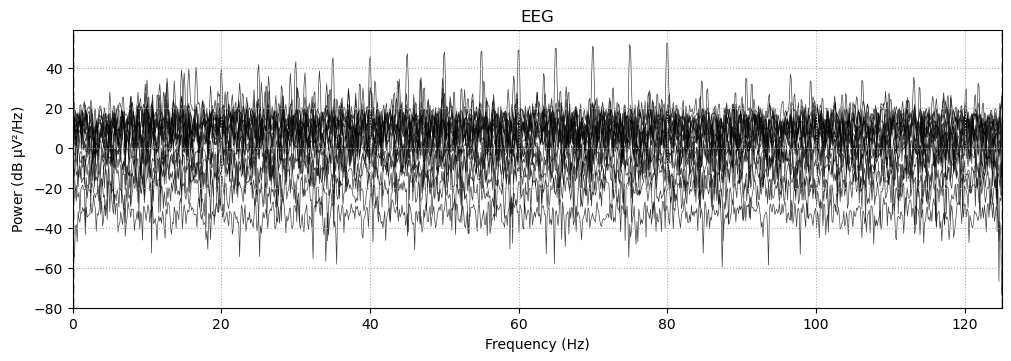

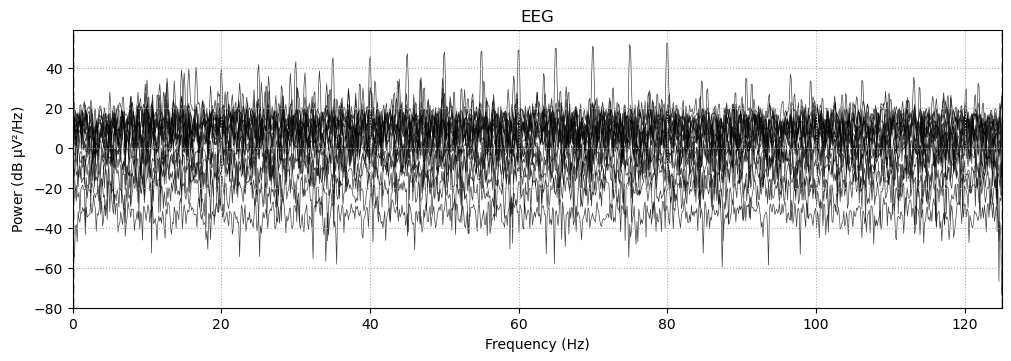

In [ ]:
#eeg_channels = BoardShim.get_eeg_channels(BoardIds.SYNTHETIC_BOARD.value)
eeg_channels = BoardShim.get_eeg_channels(BoardIds.GANGLION_NATIVE_BOARD.value)
eeg_data = data[eeg_channels, :]
eeg_data = eeg_data / 1000000 # BrainFlow returns uV, convert to V for MNE

# Creating MNE objects from brainflow data arrays
ch_types = ['eeg'] * len(eeg_channels)
ch_names = BoardShim.get_eeg_names(BoardIds.GANGLION_NATIVE_BOARD.value)
sfreq = BoardShim.get_sampling_rate(BoardIds.GANGLION_NATIVE_BOARD.value)
info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types=ch_types)
raw = mne.io.RawArray(eeg_data, info)
# output plot, not sure if it is actually live
raw.plot_psd(average=False)